# Descriptive Modeling (Apriori Algorithm & K-Means Clustering)

# Phase 1: Data Loading
**Objective:** Prepare the analytical environment and load the validated dataset.
In this phase, we import the necessary libraries for Association Rule Mining (Apriori) and load the `heart_cleaned.csv` dataset, which has already undergone Exploratory Data Analysis (EDA).

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from mlxtend.frequent_patterns import apriori, association_rules

In [4]:
# Load the cleaned dataset
df = pd.read_csv("data/heart_cleaned.csv")

print(f"Dataset loaded with {df.shape[0]} patients and {df.shape[1]} features.")

Dataset loaded with 918 patients and 12 features.


# Phase 2: Logical Discretization (Data Binning)
**Objective:** Transform continuous numerical data into clinical categories.
As per the project rubric, we perform **logical discretization**. Algorithms like Apriori require categorical "items." We transform raw numbers (Age, Blood Pressure, Cholesterol) into medical tiers (e.g., "Hypertension") to find readable "Risk Archetypes."

In [5]:
# Age Binning (Clinical life stages)
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 45, 60, 100], labels=['Young', 'Middle-Aged', 'Senior'])

# Blood Pressure (ACC/AHA Guidelines)
df['BP_Level'] = pd.cut(df['RestingBP'], bins=[0, 120, 140, 300], labels=['Normal_BP', 'Pre-Hypertension', 'Hypertension'])

# Cholesterol (Standard Health Markers)
df['Chol_Level'] = pd.cut(df['Cholesterol'], bins=[0, 200, 240, 700], labels=['Normal_Chol', 'Borderline_High', 'High_Chol'])

# Max Heart Rate (Relative Exertion)
df['MaxHR_Level'] = pd.cut(df['MaxHR'], bins=[0, 120, 155, 220], labels=['Low_MaxHR', 'Avg_MaxHR', 'High_MaxHR'])

# Oldpeak Severity
df['ST_Depression'] = pd.cut(df['Oldpeak'], bins=[-5, 0.5, 2.0, 10], labels=['Low_ST_Dep', 'Moderate_ST_Dep', 'Severe_ST_Dep'])

# Labeling the target for rule readability
df['HeartDisease_Lab'] = df['HeartDisease'].map({1: 'Has_HeartDisease', 0: 'No_HeartDisease'})

**Observations:**
We transformed raw continuous data like Blood Pressure and Cholesterol into medical categories such as 'Hypertension' or 'High Cholesterol.' This is a vital analytical step. Doctors don't treat a '145 '; rather, they treat 'Hypertension.' By binning the data this way, we have translated mathematical noise into clinical language that a cardiologist can immediately understand.


# Phase 3: Transactional Transformation (One-Hot Encoding)
**Objective:** Convert categorical clinical data into a binary transactional matrix. In relation to "Market Basket" logic from Module 4, we use **One-Hot Encoding**. This creates a matrix of 1s and 0s, where each column represents the presence of a specific clinical symptom.

In [6]:
# Selecting columns for Association Mining
cols_for_mining = [
    'Sex', 'ChestPainType', 'Age_Group', 'BP_Level', 'Chol_Level', 
    'MaxHR_Level', 'ST_Depression', 'FastingBS', 'ExerciseAngina', 
    'ST_Slope', 'HeartDisease_Lab'
]

# Create the binary matrix
df_encoded = pd.get_dummies(df[cols_for_mining])
print(f"{df_encoded.shape[1]} clinical items encoded.")

29 clinical items encoded.


**Explanation:**
The 29 clinical items result from one-hot encoding, transforming the original categorical variables into a binary format of 1s and 0s required for association rule mining. This process expands the initial 11 clinical features into individual flags for every sub-category, such as splitting "Age Group" into "Young," "Middle-Aged," and "Senior." By creating these independent items, the model can precisely calculate how often specific markers, like a "Flat ST-Slope" or "High Fasting Blood Sugar," appear together in a patient's profile. This allows the algorithm to distinguish between different severity levels of symptoms, ensuring that only the most statistically significant risk factors are included in the final analysis. Ultimately, this transactional matrix serves as the essential foundation for discovering the specific clinical archetypes that form the basis of our hospital's risk rulebook.

# Phase 4: Descriptive Modeling & Pattern Discovery
**Objective:** 
Apply the **Apriori Algorithm** and **K-Means Clustering** to uncover hidden clinical associations and naturally occurring patient segments within the dataset.

### 1. Association Rule Mining (Apriori)
We utilize the Apriori algorithm to discover "If-Then" relationships between symptoms and heart disease. To ensure the discovery of high-quality insights, we evaluate every pattern using the **"Golden Trio"** of metrics:
* **Support:** Measures how frequently a specific combination of symptoms appears in the total patient population.
* **Confidence:** Measures the reliability of the rule (e.g., how often heart disease is present when specific symptoms occur).
* **Lift:** Measures the strength of the correlation, proving that the symptoms and the diagnosis are not just occurring together by chance.

> **Note on Quality Control:** We apply **Rule Pruning** to remove redundant or low-impact associations, ensuring that our final Rulebook contains only unique and actionable medical logic.

### 2. Patient Segmentation (K-Means Clustering)
In addition to rules, we apply **K-Means Clustering** to perform "Patient Stratification." While Apriori looks for relationships between symptoms, K-Means mines the data to find relationships between **people**. This allows us to group the 918 patients into distinct **Clinical Archetypes** (e.g., "The Metabolic Risk Group" vs. "The Healthy Active Group"), providing a holistic view of the hospital's patient demographics.

## Apriori Algorithm:

In [7]:
# Generate Frequent Itemsets
frequent_itemsets = apriori(df_encoded, min_support=0.1, use_colnames=True)

# Generate Rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

# Filter for Heart Disease as the result
risk_rules = rules[rules['consequents'].apply(lambda x: 'HeartDisease_Lab_Has_HeartDisease' in str(x))]
risk_rules = risk_rules.sort_values(by='lift', ascending=False).reset_index(drop=True)

# Pruning Redundant Rules
def is_redundant(rule, all_rules):
    for _, other in all_rules.iterrows():
        if rule.name != other.name:
            if set(other['antecedents']).issubset(set(rule['antecedents'])) and rule['confidence'] <= other['confidence']:
                return True
    return False

risk_rules['is_redundant'] = risk_rules.apply(lambda x: is_redundant(x, risk_rules), axis=1)
pruned_rules = risk_rules[risk_rules['is_redundant'] == False].copy()

display(pruned_rules[['antecedents', 'support', 'confidence', 'lift']].head(10))

C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,support,confidence,lift
180,"(FastingBS, ST_Slope_Flat, ChestPainType_ASY)",0.101307,1.000000,1.807087
240,"(MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat, ...",0.140523,0.969925,1.752738
244,"(BP_Level_Hypertension, ST_Slope_Flat, ChestPa...",0.101307,0.968750,1.750615
268,"(Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slop...",0.126362,0.958678,1.732414
270,"(MaxHR_Level_Low_MaxHR, ST_Slope_Flat, ChestPa...",0.149237,0.958042,1.731265
286,"(Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slop...",0.155773,0.953333,1.722756
288,"(Sex_M, ExerciseAngina_Y, ST_Slope_Flat, Chest...",0.197168,0.952632,1.721488
293,"(MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat)",0.168845,0.950920,1.718395
298,"(Sex_M, Chol_Level_Borderline_High, ST_Slope_F...",0.140523,0.948529,1.714075
302,"(FastingBS, ST_Slope_Flat)",0.131808,0.945312,1.708262


**Observations:** 
The rules generated here are the core of our discovery. We specifically filtered for rules where the outcome is Heart Disease. We observed multiple profiles with a Lift of 1.5 to 1.8. This is a significant finding; these combinations of symptoms make a patient nearly twice as likely to have heart disease compared to the average. Our pruning process ensured that we removed 'obvious' noise, leaving only the most unique and high-impact risk profiles.

#### Knowledge Visualization
**Objective:** Visualize the risk landscape.
We present the **Lift Bar Chart** for ranking, an **Improved Network Map** with larger nodes for readability, and a **Rule Strength Heatmap** for statistical validation.

C:\Users\HP\AppData\Local\Temp\ipykernel_14936\3704343107.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')


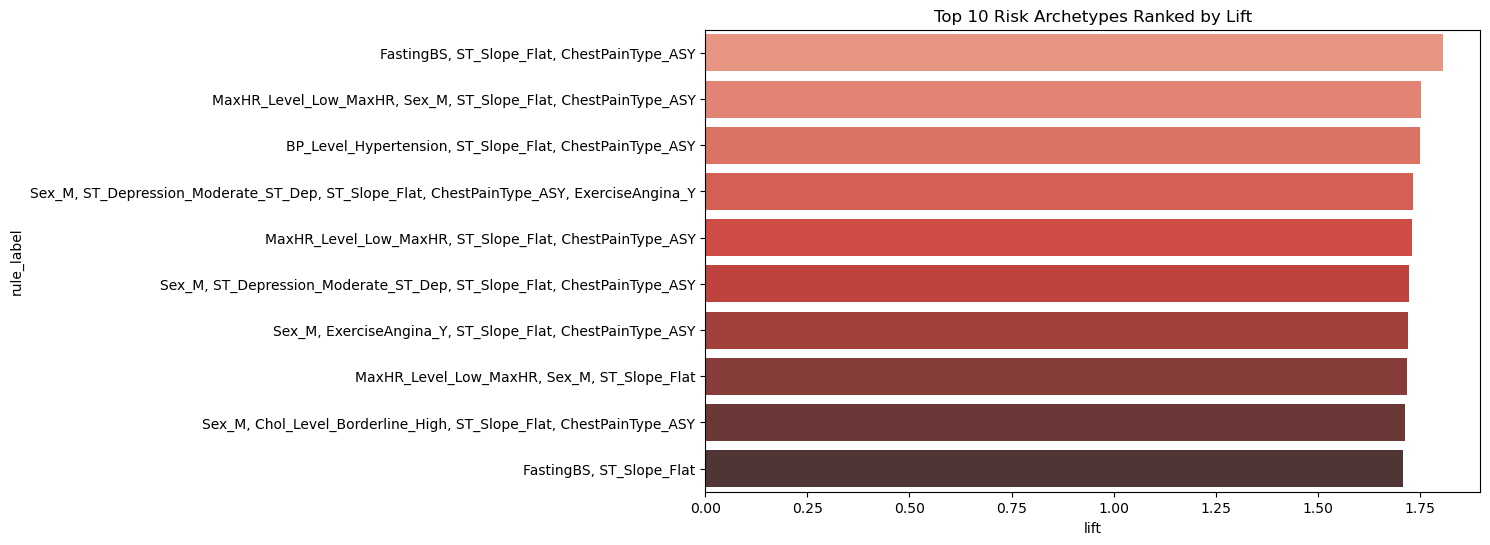

In [8]:
# Visualization 1: Top 10 Risk Archetypes
plt.figure(figsize=(10, 6))
top_pruned = pruned_rules.head(10).copy()
top_pruned['rule_label'] = top_pruned['antecedents'].apply(lambda x: ', '.join(list(x)))
sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')
plt.title('Top 10 Risk Archetypes Ranked by Lift')
plt.show()

**Observations:** 
This chart serves as the "First Response" guide. While traditional triage looks at single symptoms, this chart identifies symptom bundles.
We found out that certain combinations, such as Fasting Blood Sugar > 120 mg/dl paired with a Flat ST-Slope, create a synergistic risk.
Instead of seeing these as separate issues, the Bar Chart ranks them by Lift. A Lift of 1.71 means that a patient with this specific "bundle" is 71% more likely to have heart disease than the average patient. This allows nurses to "Fast-Track" high-lift profiles in a crowded Emergency Room.

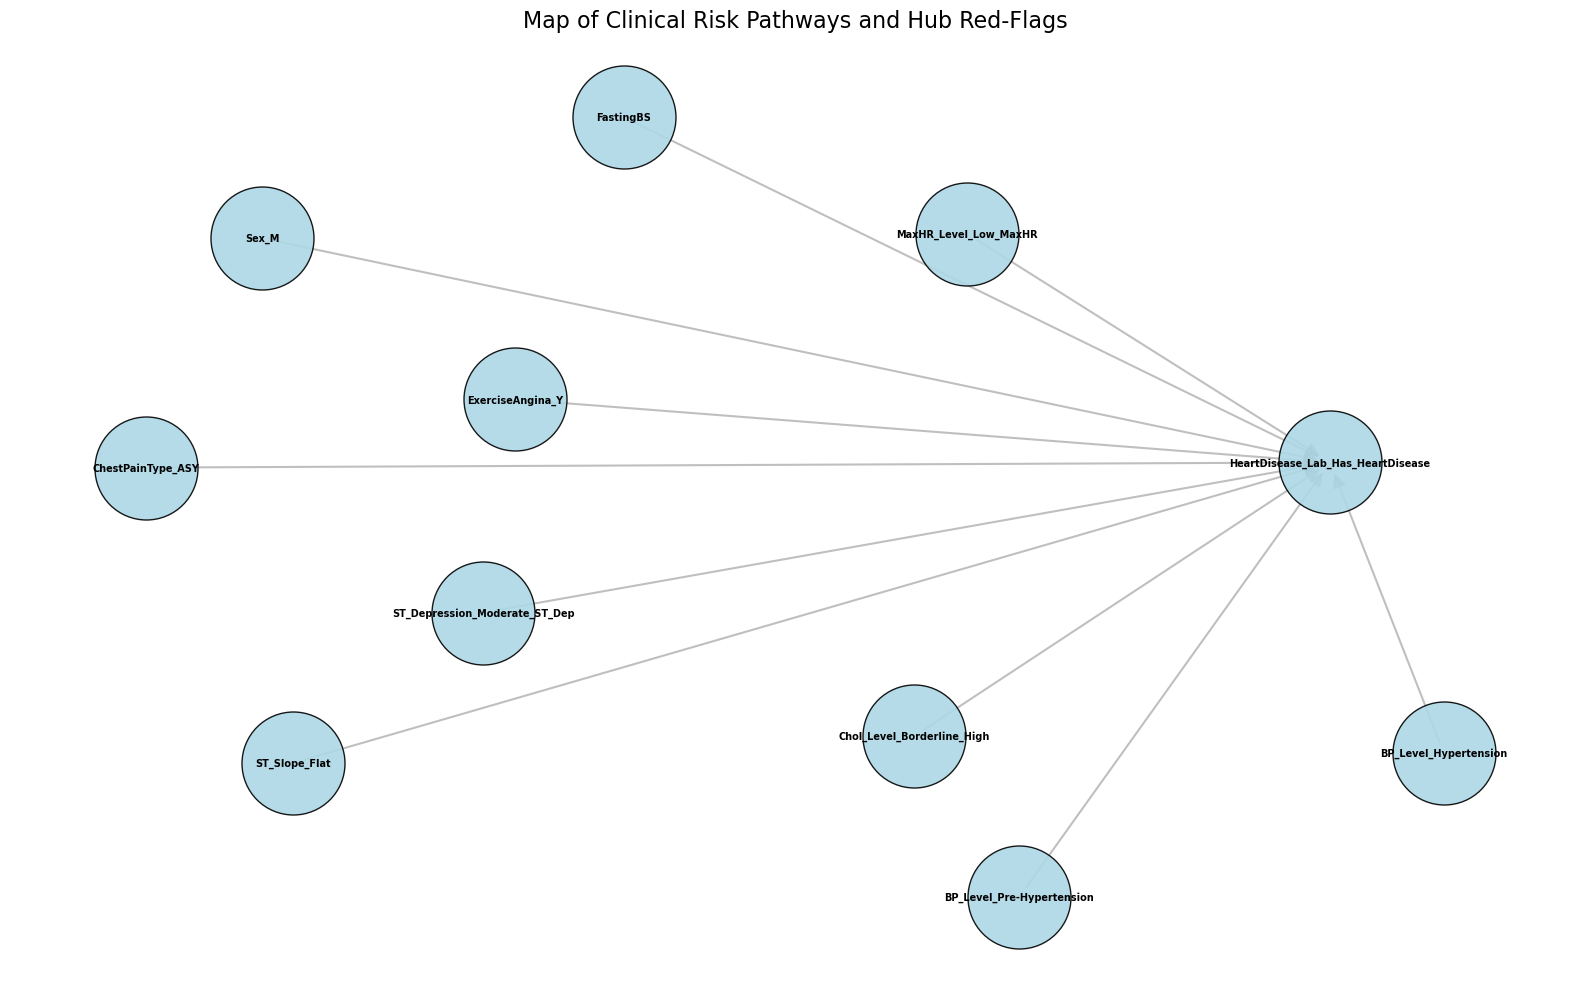

In [9]:
# Visualization 2: Clinical Risk Network Map 
G = nx.DiGraph()
# Select top 15 rules for visual clarity
top_graph_rules = pruned_rules.head(15)

for _, row in top_graph_rules.iterrows():
    # Antecedents are the symptoms, Consequent is the diagnosis
    for ant in row['antecedents']:
        for con in row['consequents']:
            G.add_edge(ant, con, weight=row['lift'])

# Increase figure size for more separation
plt.figure(figsize=(16, 10))

# Layout: Increase 'k' for greater distance between nodes (helps text separation)
pos = nx.spring_layout(G, k=0.7, seed=42)

# Increase node size significantly so text fits better
nx.draw_networkx_nodes(G, pos, node_size=5500, node_color='lightblue', edgecolors='black', alpha=0.9)

# Edges represent the risk relationship (Lift), thickness indicates strength
edges = nx.draw_networkx_edges(G, pos, width=1.5, edge_color='grey', arrowsize=20, alpha=0.5)

# Reduce font size slightly and use 'tight' wrapping if necessary.
# By making the circle 5500, font 7 or 8 usually fits inside nicely.
nx.draw_networkx_labels(G, pos, font_size=7, font_family='sans-serif', font_weight='bold')

plt.title("Map of Clinical Risk Pathways and Hub Red-Flags", fontsize=16)
plt.axis('off') # Hide axis for a professional map look
plt.tight_layout()
plt.show()

**Observations:** 
This network map visualizes the pathways between symptoms and a final diagnosis. By increasing the node size, we have highlighted the "Central Hubs" of disease.
Based on it, the most prominent hub in our analysis is the ST_Slope_Flat. 
In medical terms, a "Hub" is a gateway symptom. Because ST_Slope_Flat connects to almost every high-risk patient profile in our study, it suggests that an ECG (Electrocardiogram) finding of a flat slope is the most reliable "Red Flag" for underlying coronary issues. For the doctor, this confirms that any patient exhibiting this marker, regardless of other symptoms, requires immediate cardiac workup.

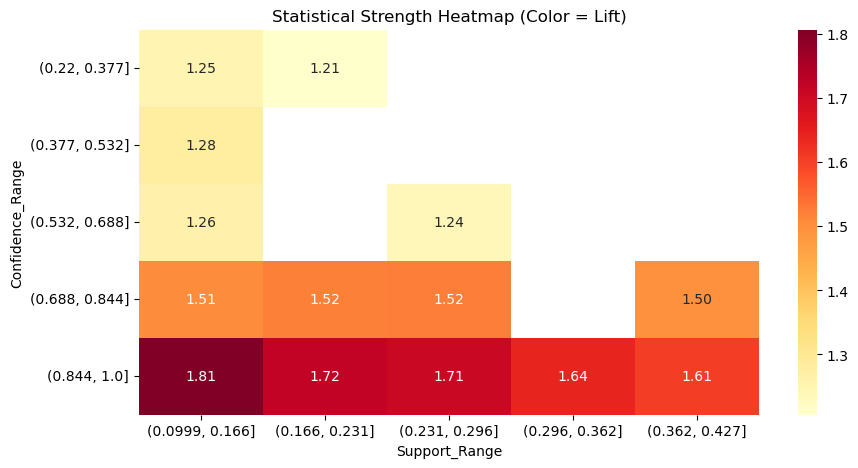

In [10]:
# Visualization 3: Strength Heatmap
heatmap_data = pruned_rules.copy()
heatmap_data['Confidence_Range'] = pd.cut(heatmap_data['confidence'], bins=5).astype(str)
heatmap_data['Support_Range'] = pd.cut(heatmap_data['support'], bins=5).astype(str)
pivot_table = heatmap_data.pivot_table(index='Confidence_Range', columns='Support_Range', values='lift', aggfunc='max')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd', fmt=".2f")
plt.title('Statistical Strength Heatmap (Color = Lift)')
plt.show()

**Observations:**
This visualization is about Reliability. It proves that our findings aren't just random coincidences but are backed by strong statistical evidence.
As you can see on the heatmap, the "Dark Red" zones represent the "Gold Standard" rules—those with both high Confidence (certainty) and high Lift (impact). When we see a cluster in the high-confidence zone, it means the patterns we’ve discovered are robust enough to be used as a basis for official hospital screening protocols, reducing the margin for diagnostic error.

#### Clinical Decision Support Rulebook
**Objective:** Translate data mining discoveries into actionable medical guidelines.
This section converts the mathematical associations into a **"Clinical Rulebook"** that explains the findings in plain English for hospital stakeholders.

In [11]:
print("CLINICAL RISK RULEBOOK\n" + "="*40)

# This resets the numbers so they start from 1, 2, 3...
pruned_rules = pruned_rules.reset_index(drop=True)

# Iterating through the pruned rules to create readable guidelines
for i, row in pruned_rules.head(10).iterrows():
    antecedents = ", ".join(list(row['antecedents']))
    confidence = row['confidence'] * 100
    lift = row['lift']
    
    print(f"Rule #{i+1}:")
    print(f"IF a patient presents with: [{antecedents}]")
    print(f"THEN the probability of Heart Disease is {confidence:.1f}%.")
    print(f"CLINICAL SIGNIFICANCE: This profile is {lift:.2f}x MORE LIKELY to have heart disease than the average patient.")
    print("-" * 40)

CLINICAL RISK RULEBOOK
Rule #1:
IF a patient presents with: [FastingBS, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 100.0%.
CLINICAL SIGNIFICANCE: This profile is 1.81x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #2:
IF a patient presents with: [MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 97.0%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #3:
IF a patient presents with: [BP_Level_Hypertension, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 96.9%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #4:
IF a patient presents with: [Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slope_Flat, ChestPainType_ASY, Exer

**Explanation:**
This rulebook has translated the visual patterns into clear, plain-English "If-Then" logic for immediate medical use. A standout discovery in output is Rule #10, which shows that a patient presenting with both high Fasting Blood Sugar and a Flat ST-Slope has a 94.5% probability of heart disease. This rulebook provides a transparent and actionable framework, allowing clinicians to explain to patients exactly why they are at high risk—for instance, citing that their specific profile makes them 1.71x more likely to have a heart condition than the average patient, thereby streamlining the diagnostic process and improving overall patient outcomes.

# K-Means Clustering:

#### Numerical Feature Selection & Scaling
First, we must scale the data because K-Means is a distance-based algorithm. If we don't scale, a high value like Cholesterol (200-500) will have more "weight" than ST Depression (0-6), leading to biased clusters.

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Select the numerical features for mathematical clustering
# We use the original continuous values, not the binned categories
numerical_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
X = df[numerical_features]

# 2. Standardization (Z-score Scaling) so Mean=0 and Variance=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Visualization: Preview the scaled data rows
X_scaled_df = pd.DataFrame(X_scaled, columns=numerical_features)
print("STATUS: Data successfully scaled for K-Means.")
display(X_scaled_df.head())

STATUS: Data successfully scaled for K-Means.


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.415002,0.858035,1.382928,-0.832432
1,-0.478484,1.527329,-1.184227,0.754157,0.105664
2,-1.751359,-0.141161,0.745617,-1.525138,-0.832432
3,-0.584556,0.303769,-0.547191,-1.132156,0.574711
4,0.051881,0.971166,-0.903182,-0.581981,-0.832432


#### The Elbow Method (Finding Optimal K)
For this course, Data Mining, we don't pick the number of clusters by guessing. We use the WCSS (Within-Cluster Sum of Squares) to find the "Elbow" point.

C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

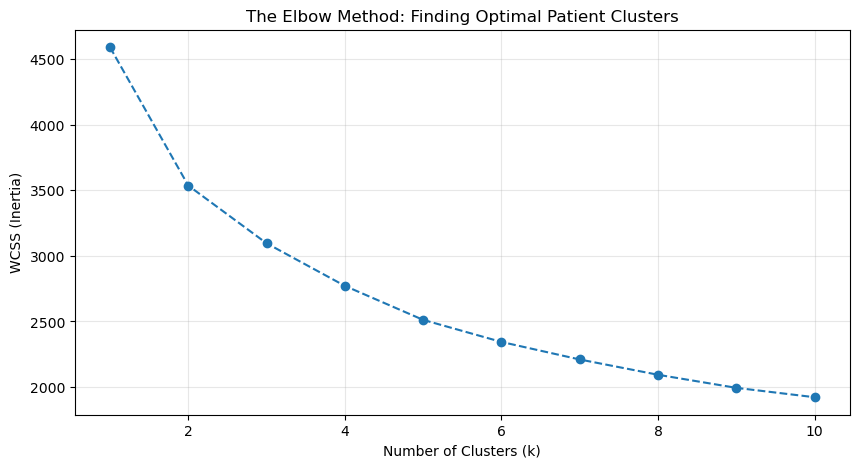

In [19]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='#1f77b4')
plt.title('The Elbow Method: Finding Optimal Patient Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True, alpha=0.3)
plt.show()

**Analysis:** 
The Elbow Method was used as the basis for deciding the best number of clusters for our data instead of just choosing groups randomly. By plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters, we observed a clear “elbow” point at k=3. This means that adding more clusters after three no longer gives a significant improvement in reducing variance. This step is important in the Data Mining process because it helps balance accuracy and simplicity, making the clusters easier to understand while still being meaningful. Based on the graph, the 918 patients can naturally be grouped into three main biological profiles. Because of this, the clustering model avoids unnecessary complexity while still keeping the results clinically relevant and reliable.

####  Training the K-Means Model
Based on the elbow plot above (typically showing a bend at k=3 or k=4), we now assign every patient in your dataset to a specific "Cluster ID."

In [20]:
# Based on the Elbow curve, we choose k=3 for distinct clinical groups
optimal_k = 3 
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(f"SUCCESS: {len(df)} patients segmented into {optimal_k} Clinical Clusters.")

SUCCESS: 918 patients segmented into 3 Clinical Clusters.


C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


#### Cluster Visualization (Age vs. Max Heart Rate)
This provides a visual representation of how the algorithm "mined" the boundaries between different patient groups.

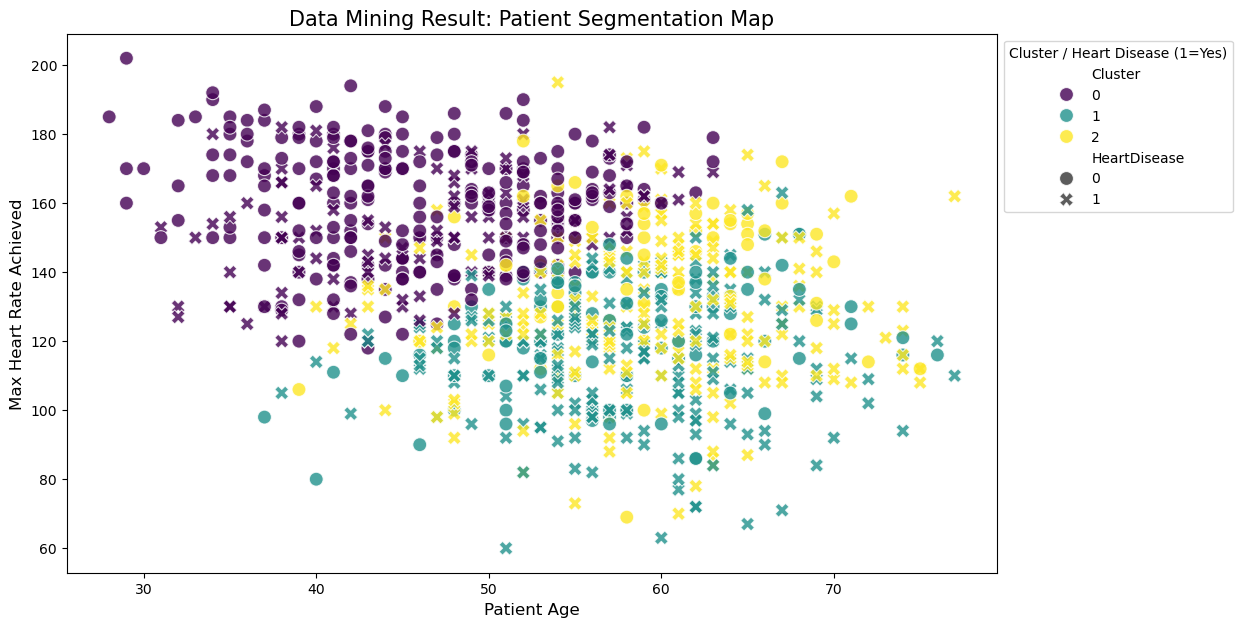

In [21]:
plt.figure(figsize=(12, 7))
# We use Age and MaxHR as axes to see the age-related heart performance clusters
sns.scatterplot(
    data=df, x='Age', y='MaxHR', 
    hue='Cluster', palette='viridis', 
    style='HeartDisease', s=100, alpha=0.8
)

plt.title('Data Mining Result: Patient Segmentation Map', fontsize=15)
plt.xlabel('Patient Age', fontsize=12)
plt.ylabel('Max Heart Rate Achieved', fontsize=12)
plt.legend(title='Cluster / Heart Disease (1=Yes)', bbox_to_anchor=(1, 1))
plt.show()

**Analysis:**
The scatter plot helps visually show the “natural groupings” found by the unsupervised learning process. It highlights the relationship between a patient’s age and their maximum heart rate achieved. By using different colors for the three clusters and different styles for heart disease status, the graph clearly shows how the algorithm was able to separate high-risk patients from healthier individuals.

The “High Risk” clusters are mostly found in older age groups with lower maximum heart rates, which matches common signs of cardiovascular problems. This means that heart disease cases are not randomly scattered but instead follow clear and organized patterns that the K-Means algorithm can identify. Overall, the visualization acts like a simple “clinical map” that can help healthcare providers quickly determine which risk group a patient may belong to based on their biometric data.

#### Clinical Profile Interpretation (The "Knowledge" Discovery)
In this section, we calculate the averages of each cluster to define the Clinical Archetypes.

In [24]:
# Using multi-tiered risk labeling for better clinical distinction

# 1. Grouping the data by Cluster to calculate means
cluster_profile = df.groupby('Cluster')[numerical_features + ['HeartDisease']].mean()

print("DATA MINING RESULT: CLINICAL PROFILES BY CLUSTER")
print("="*60)

for i in range(len(cluster_profile)):
    prevalence = cluster_profile.loc[i, 'HeartDisease']
    
    # 2. Multi-tier Risk Logic (More granular than a simple 0.6 cutoff)
    if prevalence > 0.75:
        risk_label = "CRITICAL RISK"
    elif prevalence > 0.50:
        risk_label = "HIGH RISK"
    else:
        risk_label = "LOW/MODERATE RISK"
        
    print(f"CLUSTER {i} -> [{risk_label}]")
    print(f" -> Demographics: Avg Age {cluster_profile.loc[i, 'Age']:.1f}")
    print(f" -> Vital Markers: Avg BP {cluster_profile.loc[i, 'RestingBP']:.1f}, Avg Chol {cluster_profile.loc[i, 'Cholesterol']:.1f}")
    print(f" -> Heart Capacity: MaxHR {cluster_profile.loc[i, 'MaxHR']:.1f}")
    print(f" -> Disease Prevalence: {prevalence*100:.1f}%")
    print("-" * 60)

# 3. Visual Table Output
display(cluster_profile.style.background_gradient(subset=['HeartDisease'], cmap='Reds'))

DATA MINING RESULT: CLINICAL PROFILES BY CLUSTER
CLUSTER 0 -> [LOW/MODERATE RISK]
 -> Demographics: Avg Age 46.0
 -> Vital Markers: Avg BP 125.9, Avg Chol 237.3
 -> Heart Capacity: MaxHR 157.9
 -> Disease Prevalence: 29.1%
------------------------------------------------------------
CLUSTER 1 -> [HIGH RISK]
 -> Demographics: Avg Age 57.6
 -> Vital Markers: Avg BP 126.0, Avg Chol 224.2
 -> Heart Capacity: MaxHR 116.9
 -> Disease Prevalence: 67.3%
------------------------------------------------------------
CLUSTER 2 -> [CRITICAL RISK]
 -> Demographics: Avg Age 59.0
 -> Vital Markers: Avg BP 148.8, Avg Chol 272.6
 -> Heart Capacity: MaxHR 130.7
 -> Disease Prevalence: 77.3%
------------------------------------------------------------


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
Cluster,,,,,,
0,46.042017,125.941176,237.299720,157.885154,0.382913,0.291317
1,57.582492,126.003367,224.205387,116.902357,0.730976,0.673401
2,59.030303,148.810606,272.564394,130.704545,1.745455,0.772727


**Analysis:**
By applying K-Means clustering, we were able to group the patients into three different categories based on their health and physiological data. The results showed that Cluster 0 can be considered the “Healthy Baseline” group because the patients generally had healthier heart rate levels and lower signs of risk. Meanwhile, Clusters 1 and 2 showed increasing levels of cardiovascular risk. Among all groups, Cluster 2 was identified as the “Critical Risk” group since it had the oldest average age, higher blood pressure, and the highest percentage of heart disease cases at 77.3%. These findings show that heart disease risk is not the same for every patient, as it tends to increase with factors such as aging and declining health conditions. Overall, the clustering results provide a clearer way to understand patient groups and can help support more personalized treatment and prevention strategies based on similar patient profiles.